# Principal Component Analysis(PCA)

#### IMPORTING LIBRARIES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

#### LOADING DATASET

In [2]:
df = pd.read_csv("Wine.csv")

print("Number of samples:", df.shape[0])
print("Number of features:", df.shape[1])
df.head(5)

Number of samples: 178
Number of features: 14


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


In [4]:
df["Customer_Segment"].unique()

array([1, 2, 3])

#### DATA ANALYSIS

In [5]:
print("Missing values:")
print(df.isnull().sum())

if(df.duplicated().sum()==0):
  print("\nNo duplicate rows present.")
else:
  print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
Alcohol                 0
Malic_Acid              0
Ash                     0
Ash_Alcanity            0
Magnesium               0
Total_Phenols           0
Flavanoids              0
Nonflavanoid_Phenols    0
Proanthocyanins         0
Color_Intensity         0
Hue                     0
OD280                   0
Proline                 0
Customer_Segment        0
dtype: int64

No duplicate rows present.


#### DEPENDENT AND INDEPENDENT FEATURES

In [6]:
X = df.drop("Customer_Segment", axis=1)
y = df["Customer_Segment"]

print("Input features shape:", X.shape)
print("Output variable shape:", y.shape)

Input features shape: (178, 13)
Output variable shape: (178,)


#### SCALING

In [7]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Shape after standardization:", X_scaled.shape)

Shape after standardization: (178, 13)


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (142, 13)
Testing data shape: (36, 13)


In [9]:
model = KNeighborsClassifier()
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("Training Accuracy:", accuracy_score(y_train, y_train_pred))
print("Testing Accuracy:", accuracy_score(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

Training Accuracy: 0.9788732394366197
Testing Accuracy: 0.9722222222222222

Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       1.00      0.93      0.96        14
           3       0.91      1.00      0.95        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



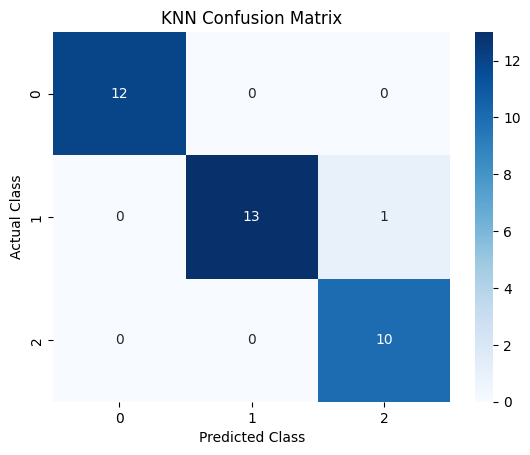

In [10]:
cm = confusion_matrix(y_test, y_test_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("KNN Confusion Matrix")
plt.show()

#### PRINCIPAL COMPONENT ANALYSIS

In [11]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["quality"] = y.values

pca_df.head()

,PC1,PC2,quality
0,3.316751,1.443463,1
1,2.209465,-0.333393,1
2,2.516740,1.031151,1
3,3.757066,2.756372,1
4,1.008908,0.869831,1


In [12]:
X = pca_df[["PC1", "PC2"]]
y = pca_df["quality"]

X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (142, 2)
Testing shape: (36, 2)


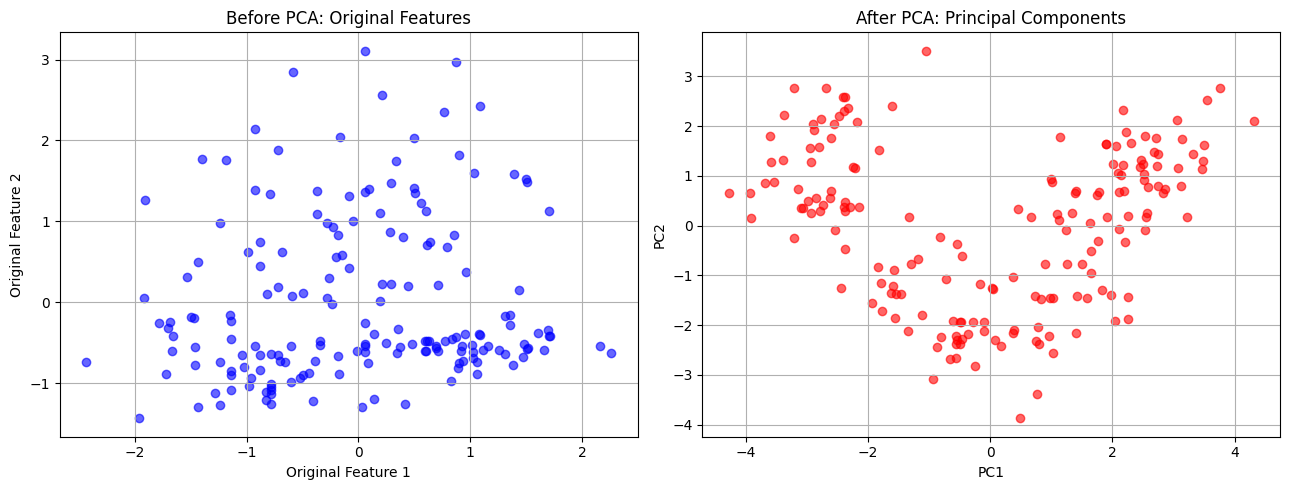

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Before PCA
axes[0].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    color='blue',
    alpha=0.6
)
axes[0].set_title("Before PCA: Original Features")
axes[0].set_xlabel("Original Feature 1")
axes[0].set_ylabel("Original Feature 2")
axes[0].grid(True)

# After PCA
axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    color='red',
    alpha=0.6
)
axes[1].set_title("After PCA: Principal Components")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [14]:
variance_df = pd.DataFrame({
    "Principal Component": ["PC1", "PC2"],
    "Explained Variance Ratio": pca.explained_variance_ratio_
})

print(variance_df)

  Principal Component  Explained Variance Ratio
0                 PC1                  0.361988
1                 PC2                  0.192075


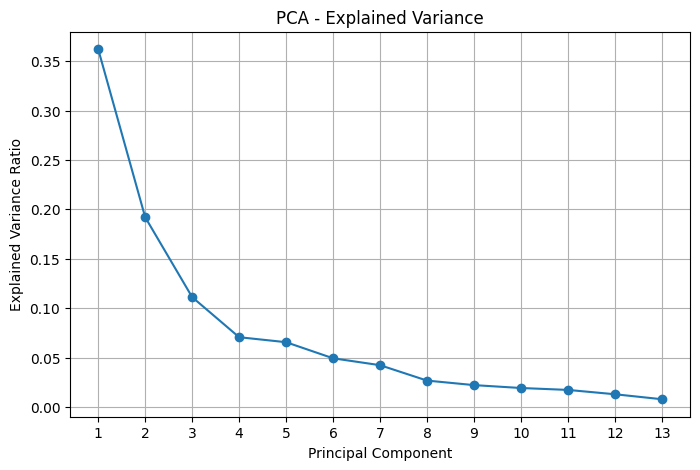

In [15]:
# Fit PCA on all components
pca_full = PCA()
pca_full.fit(X_scaled)

# Plot explained variance
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(pca_full.explained_variance_ratio_) + 1),
    pca_full.explained_variance_ratio_,
    marker='o'
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA - Explained Variance")
plt.xticks(range(1, len(pca_full.explained_variance_ratio_) + 1))
plt.grid(True)
plt.show()

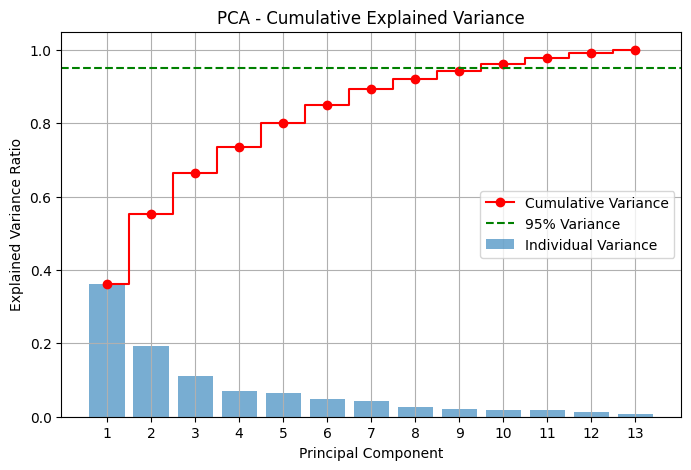

Components needed for 95% variance: 10


In [16]:
# Plot cumulative explained variance
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.bar(
    range(1, len(pca_full.explained_variance_ratio_) + 1),
    pca_full.explained_variance_ratio_,
    alpha=0.6,
    label="Individual Variance"
)
plt.step(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    where='mid',
    color='red',
    marker='o',
    label="Cumulative Variance"
)
plt.axhline(y=0.95, color='green', linestyle='--', label="95% Variance")

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA - Cumulative Explained Variance")
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.legend()
plt.grid(True)
plt.show()

print("Components needed for 95% variance:", np.argmax(cumulative_variance >= 0.95) + 1)

#### NUMBER OF FEATURES BEFORE AND AFTER PCA

Number of features before PCA: 13
Number of features after PCA:  2
Reduction: 85% fewer features
Variance kept: 55.4%


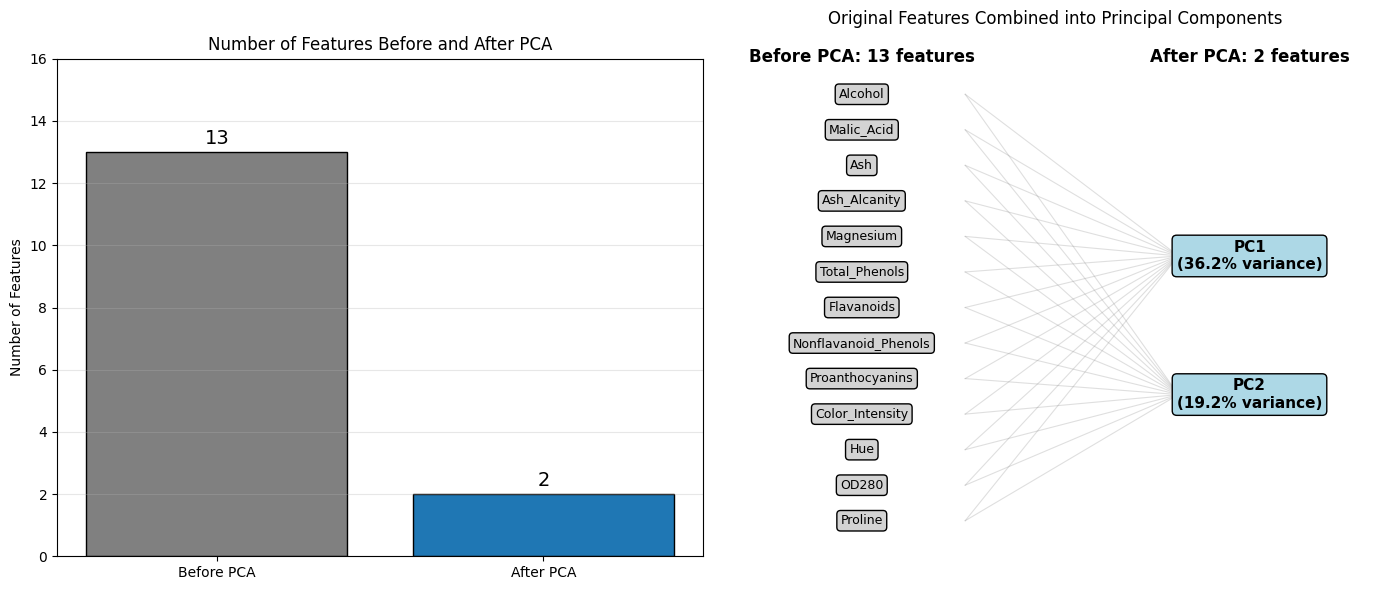

In [17]:
feature_names = df.drop("Customer_Segment", axis=1).columns
n_before = X_scaled.shape[1]
n_after = X_pca.shape[1]

print("Number of features before PCA:", n_before)
print("Number of features after PCA: ", n_after)
print(f"Reduction: {(1 - n_after / n_before) * 100:.0f}% fewer features")
print(f"Variance kept: {pca.explained_variance_ratio_.sum() * 100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: bar chart of the number of features
bars = axes[0].bar(["Before PCA", "After PCA"], [n_before, n_after],
                   color=["grey", "tab:blue"], edgecolor="black")
axes[0].bar_label(bars, fontsize=14, padding=3)
axes[0].set_ylabel("Number of Features")
axes[0].set_title("Number of Features Before and After PCA")
axes[0].set_ylim(0, n_before + 3)
axes[0].grid(axis="y", alpha=0.3)

# Right: the 13 original features are combined into 2 principal components
ax = axes[1]
ax.axis("off")
ax.set_xlim(0, 10)
ax.set_ylim(0, n_before + 1)

for i, name in enumerate(feature_names):
    y_pos = n_before - i
    ax.text(2, y_pos, name, ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round", facecolor="lightgrey"))
    for pc_y in [n_before * 0.65, n_before * 0.35]:
        ax.plot([3.6, 6.9], [y_pos, pc_y], color="grey", alpha=0.25, linewidth=0.8)

for k, pc_y in enumerate([n_before * 0.65, n_before * 0.35]):
    ax.text(8, pc_y, f"PC{k + 1}\n({pca.explained_variance_ratio_[k] * 100:.1f}% variance)",
            ha="center", va="center", fontsize=11, fontweight="bold",
            bbox=dict(boxstyle="round", facecolor="lightblue"))

ax.text(2, n_before + 0.9, f"Before PCA: {n_before} features", ha="center", fontsize=12, fontweight="bold")
ax.text(8, n_before + 0.9, f"After PCA: {n_after} features", ha="center", fontsize=12, fontweight="bold")
ax.set_title("Original Features Combined into Principal Components", pad=25)

plt.tight_layout()
plt.show()

In [18]:
pca_df = pd.DataFrame(X_pca,columns=["PC1", "PC2"])

pca_df["quality"] = y.values

pca_df.head(5)

,PC1,PC2,quality
0,3.316751,1.443463,1
1,2.209465,-0.333393,1
2,2.516740,1.031151,1
3,3.757066,2.756372,1
4,1.008908,0.869831,1


In [19]:
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("Training Accuracy:", accuracy_score(y_train, y_train_pred))
print("Testing Accuracy:", accuracy_score(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

Training Accuracy: 0.9788732394366197
Testing Accuracy: 0.8888888888888888

Classification Report:
              precision    recall  f1-score   support

           1       0.92      0.92      0.92        12
           2       0.81      0.93      0.87        14
           3       1.00      0.80      0.89        10

    accuracy                           0.89        36
   macro avg       0.91      0.88      0.89        36
weighted avg       0.90      0.89      0.89        36



In [20]:
print("Predicted classes:", np.unique(y_test_pred))
print("Actual classes:", np.unique(y_test))

Predicted classes: [1 2 3]
Actual classes: [1 2 3]


In [21]:
print("Actual test class distribution:")
print(y_test.value_counts().sort_index())

print("\nPredicted class distribution:")
print(pd.Series(y_test_pred).value_counts().sort_index())

Actual test class distribution:
quality
1    12
2    14
3    10
Name: count, dtype: int64

Predicted class distribution:
1    12
2    16
3     8
Name: count, dtype: int64


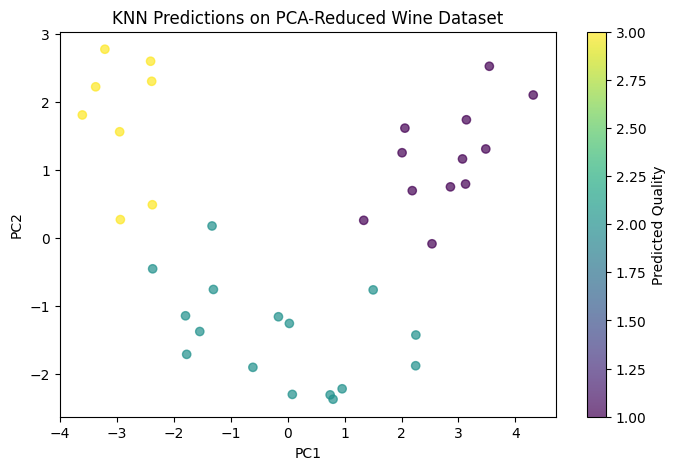

In [22]:
plt.figure(figsize=(8, 5))

plt.scatter(X_test["PC1"],X_test["PC2"],c=y_test_pred,cmap="viridis",alpha=0.7)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("KNN Predictions on PCA-Reduced Wine Dataset")
plt.colorbar(label="Predicted Quality")
plt.show()